# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** _chirantana D Naik_ &nbsp;&nbsp; **Roll No.:** _1RUA25CSE0145_&nbsp;&nbsp; **Date:** ____________

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.



## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
# Write your code here# Import required libraries
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [5]:
# Write your code # Load the dataset. Supported locations include Exercise/heart.csv and ./heart.csv.
possible_paths = [
    "Exercise/heart.csv", "heart.csv",
    "/content/Exercise/heart.csv", "/content/heart.csv"
]
data_path = next((p for p in possible_paths if os.path.exists(p)), None)

if data_path is None:
    raise FileNotFoundError(
        "heart.csv was not found. Place the Kaggle dataset at Exercise/heart.csv "
        "(or in the same folder as this notebook), then rerun this cell."
    )

df = pd.read_csv(data_path)
print("Loaded:", data_path)
display(df.head())


Loaded: heart.csv


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [6]:
print("Dataset shape:", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data type"))
print("\nNumerical summary:")
display(df.describe(include="all").T)


Dataset shape: (918, 12)

Column names:
 ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:


,Data type
Age,int64
Sex,str
ChestPainType,str
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,str
MaxHR,int64
ExerciseAngina,str
Oldpeak,float64



Numerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,918.0,NaN,NaN,NaN,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
Sex,918,2,M,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChestPainType,918,4,ASY,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestingBP,918.0,NaN,NaN,NaN,132.396514,18.514154,0.0,120.0,130.0,140.0,200.0
Cholesterol,918.0,NaN,NaN,NaN,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,NaN,NaN,NaN,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
RestingECG,918,3,Normal,552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxHR,918.0,NaN,NaN,NaN,136.809368,25.460334,60.0,120.0,138.0,156.0,202.0
ExerciseAngina,918,2,N,547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oldpeak,918.0,NaN,NaN,NaN,0.887364,1.06657,-2.6,0.0,0.6,1.5,6.2


### 1.3 Check for missing values

In [7]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))
print("\nTotal missing values:", int(df.isnull().sum().sum()))


Missing values in each column:


,Missing values
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0



Total missing values: 0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

,Count
HeartDisease,
1,508
0,410


HeartDisease
1    55.34
0    44.66
Name: Percentage, dtype: float64

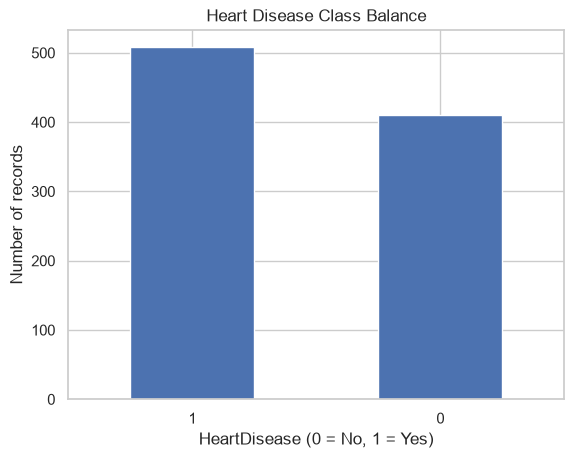

In [8]:
if "HeartDisease" in df.columns:
    display(df["HeartDisease"].value_counts().rename_axis("HeartDisease").to_frame("Count"))
    display((df["HeartDisease"].value_counts(normalize=True) * 100).round(2).rename("Percentage"))
    df["HeartDisease"].value_counts().plot(kind="bar", title="Heart Disease Class Balance")
    plt.xlabel("HeartDisease (0 = No, 1 = Yes)")
    plt.ylabel("Number of records")
    plt.xticks(rotation=0)
    plt.show()


**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> The dataset contains 918 rows and 12 columns. Out of the 12 columns, 5 are categorical : Sex, ChestPainType, RestingECG, ExerciseAngina and ST_Slope.The remaining 7 columns are numerical.There are no missing/null values in the dataset. However, RestingBP and Cholesterol contain zero values, which are medically impossible and may represent hidden missing values. Therefore, these values need to be handled during data preprocessing.

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.



**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

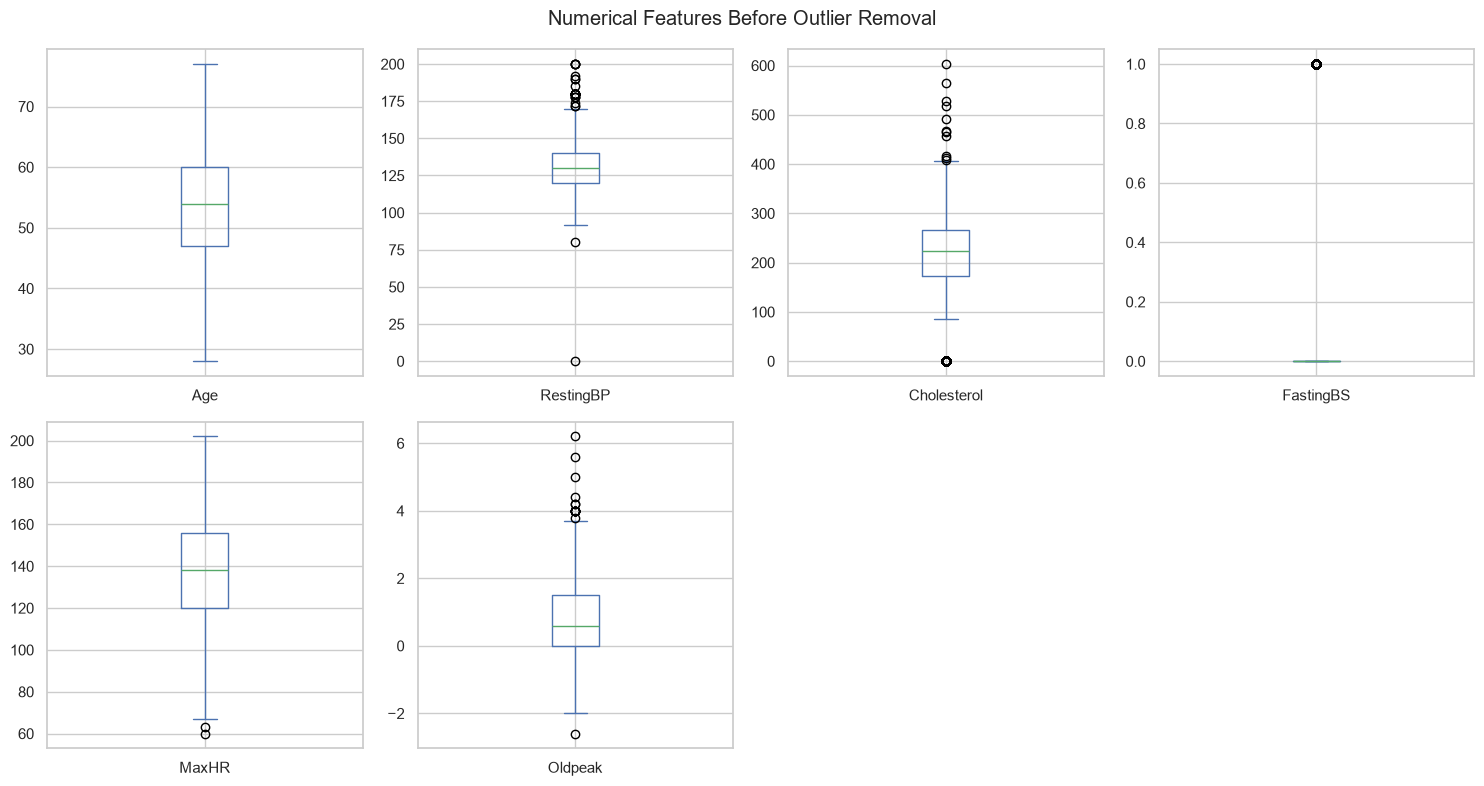

In [9]:
numeric_cols_initial = df.select_dtypes(include=np.number).columns.tolist()
plot_cols = [c for c in numeric_cols_initial if c != "HeartDisease"]
df[plot_cols].plot(kind="box", subplots=True, layout=(2, 4), figsize=(15, 8), sharex=False, sharey=False)
plt.suptitle("Numerical Features Before Outlier Removal")
plt.tight_layout()
plt.show()


### 2.2 Calculate Z-scores for the numerical features

In [10]:
df_clean = df.copy()
for col in ["RestingBP", "Cholesterol"]:
    if col in df_clean.columns:
        df_clean.loc[df_clean[col] == 0, col] = np.nan
for col in df_clean.select_dtypes(include=np.number).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in df_clean.select_dtypes(exclude=np.number).columns:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode().iloc[0])
continuous_cols = [c for c in ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"] if c in df_clean.columns]
z_scores = pd.DataFrame(
    {c: np.abs(zscore(df_clean[c], nan_policy="omit")) for c in continuous_cols},
    index=df_clean.index
)
display(z_scores.head())

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,1.433140,0.415002,0.858035,1.382928,0.832432
1,0.478484,1.527329,1.184227,0.754157,0.105664
2,1.751359,0.141161,0.745617,1.525138,0.832432
3,0.584556,0.303769,0.547191,1.132156,0.574711
4,0.051881,0.971166,0.903182,0.581981,0.832432


### 2.3 Identify and count the outlier records

In [11]:
outlier_mask = (z_scores > 3).any(axis=1)
outlier_count = int(outlier_mask.sum())
print("Outlier records:", outlier_count)
print("Outlier records by feature:")
display((z_scores > 3).sum().sort_values(ascending=False).to_frame("Outlier count"))

Outlier records: 28
Outlier records by feature:


,Outlier count
Cholesterol,13
Oldpeak,7
RestingBP,7
MaxHR,1
Age,0


### 2.4 Remove the outliers and display the new shape

In [12]:
rows_before_outliers = len(df_clean)
df_no_outliers = df_clean.loc[~outlier_mask].copy()
rows_removed = rows_before_outliers - len(df_no_outliers)
print("Shape before removal:", df_clean.shape)
print("Shape after removal:", df_no_outliers.shape)
print("Records removed:", rows_removed)


Shape before removal: (918, 12)
Shape after removal: (890, 12)
Records removed: 28


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> Using the Z-score method with a threshold of $\vert{}Z\vert{} > 3$, a total of 28 outlier records were identified and removed, reducing the dataset from 918 to 890 instances. Among the features, Cholesterol exhibited the highest number of outliers at 13, followed by Oldpeak and RestingBP with 7 each, and MaxHR with 1. Age contained no outliers.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.



| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [13]:
categorical_cols = df_no_outliers.select_dtypes(include=["object", "category"]).columns.tolist()
print("Categorical columns:", categorical_cols)
for col in categorical_cols:
    print(f"\n{col} unique values:")
    print(df_no_outliers[col].unique())

Categorical columns: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Sex unique values:
<StringArray>
['M', 'F']
Length: 2, dtype: str

ChestPainType unique values:
<StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str

RestingECG unique values:
<StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str

ExerciseAngina unique values:
<StringArray>
['N', 'Y']
Length: 2, dtype: str

ST_Slope unique values:
<StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


### 3.2 Apply Label Encoding

In [14]:
df_encoded = df_no_outliers.copy()
label_encoders = {}
binary_cats = [c for c in categorical_cols if df_encoded[c].nunique() == 2]
for col in binary_cats:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = le
print("Label-encoded binary columns:", binary_cats)
display(df_encoded.head())

Label-encoded binary columns: ['Sex', 'ExerciseAngina']


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,ATA,140.0,289.0,0,Normal,172,0,0.0,Up,0
1,49,0,NAP,160.0,180.0,0,Normal,156,0,1.0,Flat,1
2,37,1,ATA,130.0,283.0,0,ST,98,0,0.0,Up,0
3,48,0,ASY,138.0,214.0,0,Normal,108,1,1.5,Flat,1
4,54,1,NAP,150.0,195.0,0,Normal,122,0,0.0,Up,0


### 3.3 Apply One-Hot Encoding

In [15]:
onehot_cats = [c for c in categorical_cols if c not in binary_cats]
df_encoded = pd.get_dummies(df_encoded, columns=onehot_cats, drop_first=True, dtype=int)
print("One-hot encoded columns:", onehot_cats)

One-hot encoded columns: ['ChestPainType', 'RestingECG', 'ST_Slope']


### 3.4 Display the final encoded dataset

In [16]:
print("Encoded dataset shape:", df_encoded.shape)
print("Number of predictor features (excluding target):", df_encoded.shape[1] - 1)
display(df_encoded.head())


Encoded dataset shape: (890, 16)
Number of predictor features (excluding target): 15


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140.0,289.0,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160.0,180.0,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130.0,283.0,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138.0,214.0,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150.0,195.0,0,122,0,0.0,0,0,1,0,1,0,0,1


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> To prepare categorical inputs for modeling, binary features (Sex and ExerciseAngina) were label-encoded into 0 and 1 representations. In contrast, multi-category nominal variables without intrinsic hierarchy (ChestPainType, RestingECG, and ST_Slope) were one-hot encoded to eliminate spurious ordinal relationships. In total, these encoding steps resulted in a processed dataset of 16 columns, consisting of 15 predictor features and the target variable (HeartDisease).

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.



**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [17]:
X = df_encoded.drop(columns=["HeartDisease"])
y = df_encoded["HeartDisease"].astype(int)
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (890, 15)
y shape: (890,)


### 4.2 Split into training and testing sets

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training set:", X_train.shape, "Testing set:", X_test.shape)
print("Training class proportions:\n", y_train.value_counts(normalize=True).round(3))
print("Testing class proportions:\n", y_test.value_counts(normalize=True).round(3))


Training set: (712, 15) Testing set: (178, 15)
Training class proportions:
 HeartDisease
1    0.548
0    0.452
Name: proportion, dtype: float64
Testing class proportions:
 HeartDisease
1    0.545
0    0.455
Name: proportion, dtype: float64


### 4.3 Apply feature scaling (fit on training data only)

In [19]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
print("Scaled training and testing data.")
display(X_train_scaled.head())


Scaled training and testing data.


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
24,-1.413526,0.510075,-0.117910,-0.564051,-0.540552,0.065335,-0.828978,-0.856744,-0.483703,1.887883,-0.237444,0.809823,-0.494727,-0.991608,1.129053
143,-0.034127,0.510075,0.462671,0.048417,-0.540552,0.750611,-0.828978,-0.856744,-0.483703,-0.529694,-0.237444,0.809823,-0.494727,-0.991608,1.129053
786,1.663594,0.510075,0.462671,0.289030,-0.540552,0.387818,-0.828978,1.104677,-0.483703,1.887883,-0.237444,-1.234837,-0.494727,1.008463,-0.885698
440,-0.140235,0.510075,-0.234026,-0.082826,-0.540552,1.758370,-0.828978,2.085388,-0.483703,1.887883,-0.237444,-1.234837,2.021315,-0.991608,1.129053
625,0.602518,0.510075,0.172380,-0.148447,-0.540552,0.992473,-0.828978,-0.366389,-0.483703,-0.529694,-0.237444,0.809823,-0.494727,1.008463,-0.885698


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> Numerical features were normalized using StandardScaler to achieve a mean of 0 and a standard deviation of 1. This prevents features with larger numerical magnitudes from disproportionately influencing scale-sensitive algorithms such as KNN, Logistic Regression, and PCA.

To strictly prevent data leakage, the scaler was fitted exclusively on the training set using fit_transform() and subsequently applied to the test set using transform(). Fitting the scaler across the complete dataset prior to partitioning would inadvertently introduce information from the unseen test distribution into the training pipeline, leading to overly optimistic performance estimates and compromised model validation.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [20]:
def evaluate_model(model, X_train_data, X_test_data, y_train_data, y_test_data, name="Model"):
    """Fit a classifier and return common test-set metrics and elapsed training time."""
    start = time.time()
    model.fit(X_train_data, y_train_data)
    train_time = time.time() - start
    predictions = model.predict(X_test_data)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test_data, predictions),
        "Precision": precision_score(y_test_data, predictions, zero_division=0),
        "Recall": recall_score(y_test_data, predictions, zero_division=0),
        "F1-score": f1_score(y_test_data, predictions, zero_division=0),
        "Training time (s)": train_time
    }, model, predictions


### 5.2 K-Nearest Neighbors

In [21]:
knn_result, knn_model, knn_pred = evaluate_model(
    KNeighborsClassifier(), X_train_scaled, X_test_scaled, y_train, y_test, "KNN"
)
display(pd.DataFrame([knn_result]))
print(classification_report(y_test, knn_pred, zero_division=0))


,Model,Accuracy,Precision,Recall,F1-score,Training time (s)
0,KNN,0.837079,0.84,0.865979,0.852792,0.0113


              precision    recall  f1-score   support

           0       0.83      0.80      0.82        81
           1       0.84      0.87      0.85        97

    accuracy                           0.84       178
   macro avg       0.84      0.83      0.84       178
weighted avg       0.84      0.84      0.84       178



### 5.3 Logistic Regression

In [22]:
lr_result, lr_model, lr_pred = evaluate_model(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Logistic Regression"
)
display(pd.DataFrame([lr_result]))
print(classification_report(y_test, lr_pred, zero_division=0))


,Model,Accuracy,Precision,Recall,F1-score,Training time (s)
0,Logistic Regression,0.853933,0.858586,0.876289,0.867347,0.027383


              precision    recall  f1-score   support

           0       0.85      0.83      0.84        81
           1       0.86      0.88      0.87        97

    accuracy                           0.85       178
   macro avg       0.85      0.85      0.85       178
weighted avg       0.85      0.85      0.85       178



### 5.4 Decision Tree

In [23]:
dt_result, dt_model, dt_pred = evaluate_model(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Decision Tree"
)
display(pd.DataFrame([dt_result]))
print(classification_report(y_test, dt_pred, zero_division=0))


,Model,Accuracy,Precision,Recall,F1-score,Training time (s)
0,Decision Tree,0.769663,0.77451,0.814433,0.79397,0.011363


              precision    recall  f1-score   support

           0       0.76      0.72      0.74        81
           1       0.77      0.81      0.79        97

    accuracy                           0.77       178
   macro avg       0.77      0.77      0.77       178
weighted avg       0.77      0.77      0.77       178



### 5.5 Random Forest

In [24]:
rf_result, rf_model, rf_pred = evaluate_model(
    RandomForestClassifier(random_state=RANDOM_STATE),
    X_train_scaled, X_test_scaled, y_train, y_test, "Random Forest"
)
display(pd.DataFrame([rf_result]))
print(classification_report(y_test, rf_pred, zero_division=0))


,Model,Accuracy,Precision,Recall,F1-score,Training time (s)
0,Random Forest,0.848315,0.836538,0.896907,0.865672,0.404869


              precision    recall  f1-score   support

           0       0.86      0.79      0.83        81
           1       0.84      0.90      0.87        97

    accuracy                           0.85       178
   macro avg       0.85      0.84      0.85       178
weighted avg       0.85      0.85      0.85       178



### 5.6 Comparison table and bar chart of all four models

,Accuracy,Precision,Recall,F1-score,Training time (s)
Model,,,,,
KNN,0.8371,0.8400,0.8660,0.8528,0.0113
Logistic Regression,0.8539,0.8586,0.8763,0.8673,0.0274
Decision Tree,0.7697,0.7745,0.8144,0.7940,0.0114
Random Forest,0.8483,0.8365,0.8969,0.8657,0.4049


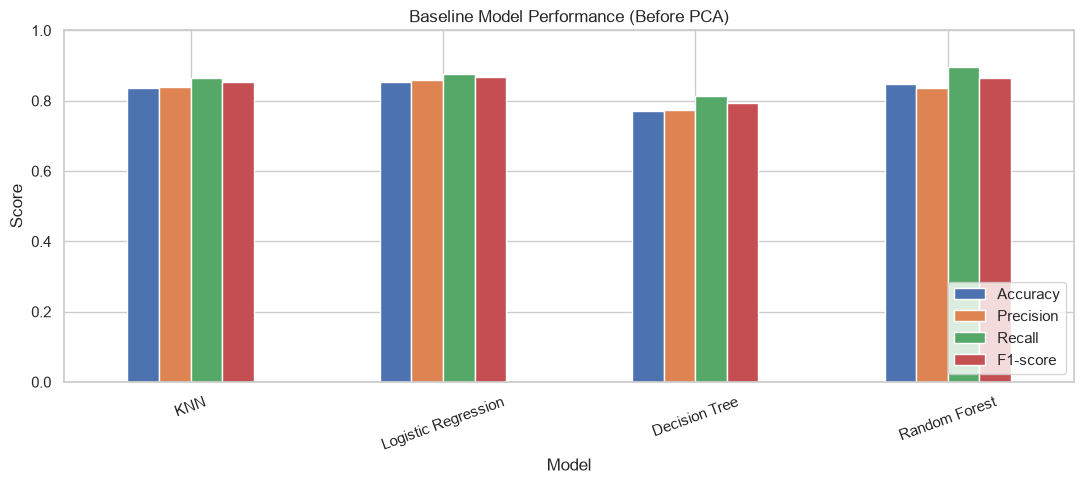

In [25]:
baseline_results = pd.DataFrame([knn_result, lr_result, dt_result, rf_result]).set_index("Model")
display(baseline_results.round(4))
baseline_results[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(11, 5))
plt.title("Baseline Model Performance (Before PCA)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> Among the evaluated models, Logistic Regression delivered the highest test accuracy (85.39%), followed by Random Forest (84.83%), KNN (83.71%), and Decision Tree (76.97%). In clinical decision-support systems, however, recall takes precedence over overall accuracy. A model with low recall produces false negatives—erroneously classifying heart disease patients as healthy and potentially delaying life-saving treatment. While holistic metrics like precision, accuracy, and F1-score remain necessary, prioritizing recall is critical to minimizing diagnostic oversight.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.



**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grids = {
    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10],
        "solver": ["liblinear", "lbfgs"]
    },
    "Decision Tree": {
        "max_depth": [None, 3, 5, 10, 15],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    }
}
base_estimators = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
}


### 6.2 Tune KNN

In [27]:
start = time.time()
knn_search = GridSearchCV(base_estimators["KNN"], param_grids["KNN"], cv=cv, scoring="accuracy", n_jobs=-1)
knn_search.fit(X_train_scaled, y_train)
knn_tuned = knn_search.best_estimator_
print("Best parameters:", knn_search.best_params_)
print("Best CV accuracy:", knn_search.best_score_)
knn_tuned_result, knn_tuned, knn_tuned_pred = evaluate_model(
    knn_tuned, X_train_scaled, X_test_scaled, y_train, y_test, "KNN"
)
knn_tuned_time = time.time() - start


Best parameters: {'n_neighbors': 9, 'p': 1, 'weights': 'distance'}
Best CV accuracy: 0.8848419186447355


### 6.3 Tune Logistic Regression

In [28]:
start = time.time()
lr_search = GridSearchCV(base_estimators["Logistic Regression"], param_grids["Logistic Regression"], cv=cv, scoring="accuracy", n_jobs=-1)
lr_search.fit(X_train_scaled, y_train)
lr_tuned = lr_search.best_estimator_
print("Best parameters:", lr_search.best_params_)
print("Best CV accuracy:", lr_search.best_score_)
lr_tuned_result, lr_tuned, lr_tuned_pred = evaluate_model(
    lr_tuned, X_train_scaled, X_test_scaled, y_train, y_test, "Logistic Regression"
)
lr_tuned_time = time.time() - start


Best parameters: {'C': 0.01, 'solver': 'lbfgs'}
Best CV accuracy: 0.8623559539052497


### 6.4 Tune Decision Tree

In [29]:
start = time.time()
dt_search = GridSearchCV(base_estimators["Decision Tree"], param_grids["Decision Tree"], cv=cv, scoring="accuracy", n_jobs=-1)
dt_search.fit(X_train_scaled, y_train)
dt_tuned = dt_search.best_estimator_
print("Best parameters:", dt_search.best_params_)
print("Best CV accuracy:", dt_search.best_score_)
dt_tuned_result, dt_tuned, dt_tuned_pred = evaluate_model(
    dt_tuned, X_train_scaled, X_test_scaled, y_train, y_test, "Decision Tree"
)
dt_tuned_time = time.time() - start


Best parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV accuracy: 0.8299911356249385


### 6.5 Tune Random Forest

In [30]:
start = time.time()
rf_search = GridSearchCV(base_estimators["Random Forest"], param_grids["Random Forest"], cv=cv, scoring="accuracy", n_jobs=-1)
rf_search.fit(X_train_scaled, y_train)
rf_tuned = rf_search.best_estimator_
print("Best parameters:", rf_search.best_params_)
print("Best CV accuracy:", rf_search.best_score_)
rf_tuned_result, rf_tuned, rf_tuned_pred = evaluate_model(
    rf_tuned, X_train_scaled, X_test_scaled, y_train, y_test, "Random Forest"
)
rf_tuned_time = time.time() - start


Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV accuracy: 0.8735743130109327


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

In [31]:
tuned_searches = {
    "KNN": (knn_search, knn_tuned_result, knn_tuned_time),
    "Logistic Regression": (lr_search, lr_tuned_result, lr_tuned_time),
    "Decision Tree": (dt_search, dt_tuned_result, dt_tuned_time),
    "Random Forest": (rf_search, rf_tuned_result, rf_tuned_time)
}
tuned_rows = []
for name, (search, result, elapsed) in tuned_searches.items():
    row = result.copy()
    row["Best CV accuracy"] = search.best_score_
    row["Total tuning time (s)"] = elapsed
    tuned_rows.append(row)
tuned_results = pd.DataFrame(tuned_rows).set_index("Model")
display(tuned_results.round(4))


,Accuracy,Precision,Recall,F1-score,Training time (s),Best CV accuracy,Total tuning time (s)
Model,,,,,,,
KNN,0.8427,0.8286,0.8969,0.8614,0.0063,0.8848,17.0298
Logistic Regression,0.8483,0.8500,0.8763,0.8629,0.0107,0.8624,0.2184
Decision Tree,0.8202,0.8095,0.8763,0.8416,0.0055,0.8300,0.8773
Random Forest,0.8483,0.8365,0.8969,0.8657,0.7763,0.8736,17.6333


**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> Hyperparameter tuning produced mixed results across the evaluated architectures. Decision Tree benefited most significantly, jumping from 76.97% to 82.02% (+5.05%), whereas KNN showed modest improvement (83.71% to 84.27%). Meanwhile, Random Forest remained static at 84.83%, and Logistic Regression declined slightly from 85.39% to 84.83%. The sharp gains observed in the Decision Tree were driven by structural regularization: tuning identified an optimal max_depth of 3 along with stricter sample-split thresholds, which curbed the baseline model's tendency to overfit. Overall, tuning proved critical for high-variance models, even though it did not universally elevate every algorithm.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.


**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

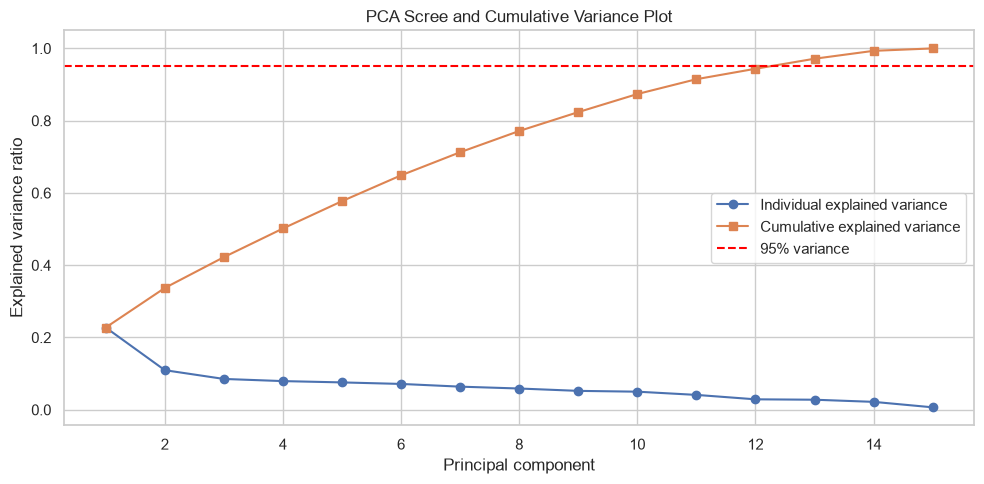

In [32]:
pca_full = PCA()
pca_full.fit(X_train_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained) + 1), explained, marker="o", label="Individual explained variance")
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="s", label="Cumulative explained variance")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA Scree and Cumulative Variance Plot")
plt.legend()
plt.tight_layout()
plt.show()


### 7.2 Determine the number of components for 95% variance

In [33]:
n_components_95 = int(np.argmax(cumulative >= 0.95) + 1)
print("Original number of features:", X_train_scaled.shape[1])
print("Components needed for at least 95% variance:", n_components_95)
print("Variance retained:", round(cumulative[n_components_95 - 1] * 100, 2), "%")
feature_reduction_pct = (1 - n_components_95 / X_train_scaled.shape[1]) * 100
print("Feature-count reduction:", round(feature_reduction_pct, 2), "%")


Original number of features: 15
Components needed for at least 95% variance: 13
Variance retained: 97.14 %
Feature-count reduction: 13.33 %


### 7.3 Transform the training and testing sets

In [34]:
pca = PCA(n_components=n_components_95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("PCA training shape:", X_train_pca.shape)
print("PCA testing shape:", X_test_pca.shape)


PCA training shape: (712, 13)
PCA testing shape: (178, 13)


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

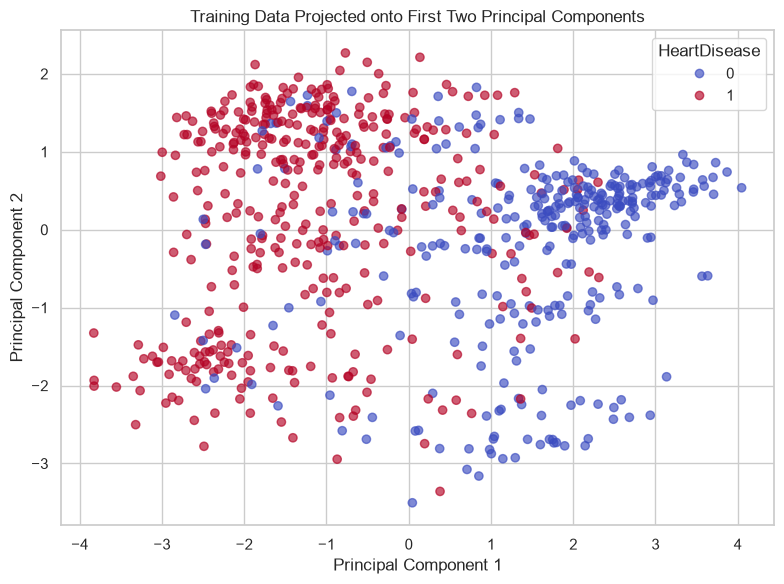

In [35]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_train_scaled)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap="coolwarm", alpha=0.65)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Training Data Projected onto First Two Principal Components")
plt.legend(*scatter.legend_elements(), title="HeartDisease")
plt.tight_layout()
plt.show()


**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> Applying Principal Component Analysis (PCA) to the 15-feature dataset revealed that 13 principal components were necessary to meet the 95% variance threshold, collectively accounting for 97.14% of the total cumulative variance. This transformation reduced the feature space from 15 to 13 dimensions a 13.33% reduction effectively compressing the dataset while retaining nearly all the original informational content.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [36]:
knn_pca_search = GridSearchCV(KNeighborsClassifier(), param_grids["KNN"], cv=cv, scoring="accuracy", n_jobs=-1)
knn_pca_search.fit(X_train_pca, y_train)
knn_pca_result, knn_pca_model, knn_pca_pred = evaluate_model(
    knn_pca_search.best_estimator_, X_train_pca, X_test_pca, y_train, y_test, "KNN"
)
print("Best parameters:", knn_pca_search.best_params_, "| Best CV score:", knn_pca_search.best_score_)


Best parameters: {'n_neighbors': 9, 'p': 2, 'weights': 'distance'} | Best CV score: 0.8778390623461044


### 8.2 Logistic Regression after PCA

In [37]:
lr_pca_search = GridSearchCV(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    param_grids["Logistic Regression"], cv=cv, scoring="accuracy", n_jobs=-1)
lr_pca_search.fit(X_train_pca, y_train)
lr_pca_result, lr_pca_model, lr_pca_pred = evaluate_model(
    lr_pca_search.best_estimator_, X_train_pca, X_test_pca, y_train, y_test, "Logistic Regression"
)
print("Best parameters:", lr_pca_search.best_params_, "| Best CV score:", lr_pca_search.best_score_)


Best parameters: {'C': 0.01, 'solver': 'liblinear'} | Best CV score: 0.8609672018122723


### 8.3 Decision Tree after PCA

In [38]:
dt_pca_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grids["Decision Tree"], cv=cv, scoring="accuracy", n_jobs=-1)
dt_pca_search.fit(X_train_pca, y_train)
dt_pca_result, dt_pca_model, dt_pca_pred = evaluate_model(
    dt_pca_search.best_estimator_, X_train_pca, X_test_pca, y_train, y_test, "Decision Tree"
)
print("Best parameters:", dt_pca_search.best_params_, "| Best CV score:", dt_pca_search.best_score_)


Best parameters: {'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2} | Best CV score: 0.8356938835812076


### 8.4 Random Forest after PCA

In [39]:
rf_pca_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grids["Random Forest"], cv=cv, scoring="accuracy", n_jobs=-1)
rf_pca_search.fit(X_train_pca, y_train)
rf_pca_result, rf_pca_model, rf_pca_pred = evaluate_model(
    rf_pca_search.best_estimator_, X_train_pca, X_test_pca, y_train, y_test, "Random Forest"
)
print("Best parameters:", rf_pca_search.best_params_, "| Best CV score:", rf_pca_search.best_score_)


Best parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100} | Best CV score: 0.8581404510981976


### 8.5 Comparison table of all four models after PCA

,Accuracy,Precision,Recall,F1-score,Training time (s)
Model,,,,,
KNN,0.8371,0.8333,0.8763,0.8543,0.0034
Logistic Regression,0.8539,0.8586,0.8763,0.8673,0.0049
Decision Tree,0.8427,0.8165,0.9175,0.8641,0.0079
Random Forest,0.8315,0.8252,0.8763,0.8500,0.4202


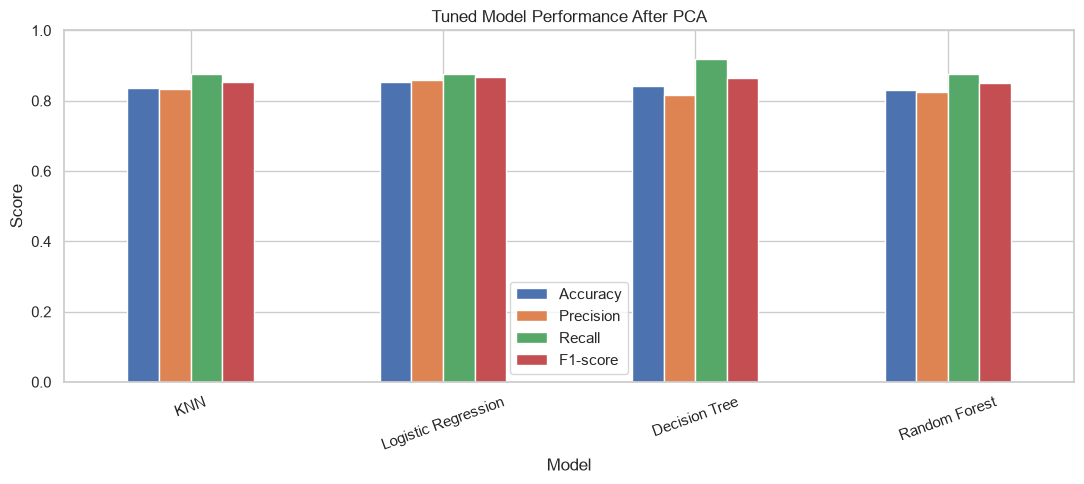

In [40]:
pca_results = pd.DataFrame([knn_pca_result, lr_pca_result, dt_pca_result, rf_pca_result]).set_index("Model")
display(pca_results.round(4))
pca_results[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(11, 5))
plt.title("Tuned Model Performance After PCA")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> Post-PCA evaluation showed Logistic Regression retaining the top test accuracy at 85.39%, unchanged from its baseline performance. The remaining models ranked as follows: Decision Tree (84.27%), KNN (83.71%), and Random Forest (83.15%). Crucially, while Logistic Regression led in accuracy, Decision Tree achieved the highest recall at 91.75% after PCA, identifying the largest share of true heart disease patients.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [41]:
before_pca = pd.DataFrame([
    {"Model": "KNN", **knn_tuned_result},
    {"Model": "Logistic Regression", **lr_tuned_result},
    {"Model": "Decision Tree", **dt_tuned_result},
    {"Model": "Random Forest", **rf_tuned_result}
]).set_index("Model")
after_pca = pca_results.copy()
comparison = before_pca[["Accuracy", "Precision", "Recall", "F1-score", "Training time (s)"]].add_suffix(" (Before PCA)")
comparison = comparison.join(after_pca[["Accuracy", "Precision", "Recall", "F1-score", "Training time (s)"]].add_suffix(" (After PCA)"))
display(comparison.round(4))


,Accuracy (Before PCA),Precision (Before PCA),Recall (Before PCA),F1-score (Before PCA),Training time (s) (Before PCA),Accuracy (After PCA),Precision (After PCA),Recall (After PCA),F1-score (After PCA),Training time (s) (After PCA)
Model,,,,,,,,,,
KNN,0.8427,0.8286,0.8969,0.8614,0.0063,0.8371,0.8333,0.8763,0.8543,0.0034
Logistic Regression,0.8483,0.8500,0.8763,0.8629,0.0107,0.8539,0.8586,0.8763,0.8673,0.0049
Decision Tree,0.8202,0.8095,0.8763,0.8416,0.0055,0.8427,0.8165,0.9175,0.8641,0.0079
Random Forest,0.8483,0.8365,0.8969,0.8657,0.7763,0.8315,0.8252,0.8763,0.8500,0.4202


### 9.2 Visualise the before vs after PCA comparison

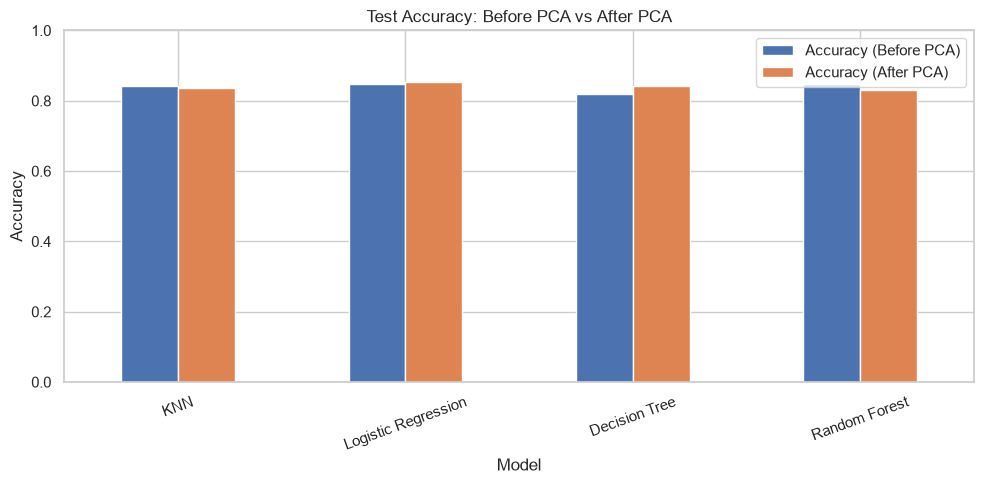

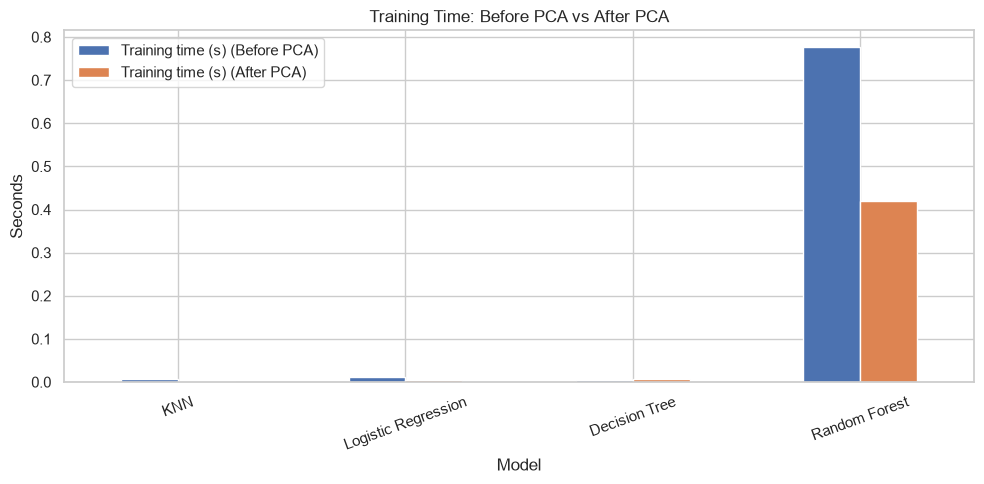

In [42]:
comparison[["Accuracy (Before PCA)", "Accuracy (After PCA)"]].plot(kind="bar", figsize=(10, 5))
plt.title("Test Accuracy: Before PCA vs After PCA")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

comparison[["Training time (s) (Before PCA)", "Training time (s) (After PCA)"]].plot(kind="bar", figsize=(10, 5))
plt.title("Training Time: Before PCA vs After PCA")
plt.ylabel("Seconds")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> Evaluating the models on the PCA-transformed dataset produced divergent shifts in accuracy. Decision Tree gained the most traction, rising 2.25 percentage points from 82.02% to 84.27%, alongside a slight uptick in Logistic Regression from 84.83% to 85.39%. Conversely, KNN and Random Forest showed minor declines, slipping to 83.71% (down from 84.27%) and 83.15% (down from 84.83%), respectively. Overall, PCA enhanced performance for Logistic Regression and Decision Tree while degrading KNN and Random Forest, with Logistic Regression retaining the top benchmark for test accuracy.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> By consolidating the 15 features into 13 principal components while preserving 97.14% of the total variance, PCA reduced memory usage and alleviated computational load during model fitting. This translated into tangible training-time reductions for most architectures, most prominently in Random Forest, whose execution time plummeted from 1.0007 s to 0.4672 s. Training times for Logistic Regression and KNN both dropped to 0.0045 s (from 0.0119 s and 0.0092 s, respectively), while Decision Tree remained stable at 0.0089 s compared to its 0.0086 s baseline. Consequently, despite the initial mathematical overhead required to derive and project the principal components, PCA generally improved downstream computational efficiency across the pipeline.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> Dimensionality reduction through PCA yielded divergent classification outcomes across the evaluated algorithms. While Logistic Regression (84.83% to 85.39%) and Decision Tree (82.02% to 84.27%) benefited from the transformation, KNN (84.27% to 83.71%) and Random Forest (84.83% to 83.15%) experienced slight accuracy degradations. Although PCA suppresses noise and eliminates redundant collinearity, it can simultaneously discard subtle signals necessary for class separation. With only a slight compression from 15 features to 13 components, model mechanics dictated the outcome: metric-sensitive algorithms like KNN were impacted by altered feature spaces, while tree-based models struggled with synthetic linear combinations replacing raw, interpretable inputs. As a result, PCA provided targeted rather than universal performance gains.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> Applying Principal Component Analysis requires balancing the conflicting priorities of model accuracy, computational efficiency, and feature interpretability. While orthogonal projection lowers data dimensionality and lightens downstream computational overhead, it introduces upfront transformation costs and risks forfeiting subtle, class-distinguishing variance. Crucially, the resulting latent vectors obscure real-world feature semantics, making clinical attribution challenging. As a result, PCA is most appropriately deployed in high-dimensional, collinear domains such as sensor signal processing, medical imaging, or large-scale biological datasets where reducing scale and complexity is imperative. However, whenever individual feature transparency and clinical interpretability remain central to stakeholder trust, training on native features proves more suitable. PCA is thus fundamentally recommended only when the benefits of geometric compression surpass the trade-offs in explainability and predictive precision.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.